# Final paper results analysis

Generates the final paper-facing results assets from the latest single-shot, corrected abundant-data, and oracle-baseline runs.

Main story: control performance in the two data regimes, mechanism-targeted intervention on the structured cases, direct recovery of the influence matrix, and one representative node-level trajectory. A compact two-panel schematic is also generated to replace the old six-panel structured-benchmark illustration.

In [14]:

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 260)


def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "opinion_dynamics").exists():
            return candidate
    raise RuntimeError("Could not find repository root.")


REPO_ROOT = find_repo_root()
RESULTS_ROOT = REPO_ROOT / "opinion_dynamics" / "experiments" / "results"

SS_DIR = RESULTS_ROOT / "experiment_2026_09_30_final_unregularized_single_shot"
AB_DIR = RESULTS_ROOT / "experiment_2026_10_04_final_unregularized_abundant_matched_distribution_25x20_fit20k"
BASELINE_DIR = RESULTS_ROOT / "experiment_2026_09_28_true_graph_static_and_analytic_baselines"

OUT_DIR = RESULTS_ROOT / "paper_analysis_2026_10_12_results_storyline_fixed"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

required = [
    SS_DIR / "COMPUTATION_COMPLETE.json",
    SS_DIR / "RUN_MANIFEST.json",
    SS_DIR / "combined_summary.csv",
    AB_DIR / "COMPUTATION_COMPLETE.json",
    AB_DIR / "combined_summary.csv",
    BASELINE_DIR / "COMPUTATION_COMPLETE.json",
    BASELINE_DIR / "true_graph_static_all_195.csv",
    BASELINE_DIR / "true_graph_analytic_supported_90.csv",
]
for path in required:
    if not path.exists():
        raise FileNotFoundError(path)

ss_complete = json.loads((SS_DIR / "COMPUTATION_COMPLETE.json").read_text(encoding="utf-8"))
ab_complete = json.loads((AB_DIR / "COMPUTATION_COMPLETE.json").read_text(encoding="utf-8"))
base_complete = json.loads((BASELINE_DIR / "COMPUTATION_COMPLETE.json").read_text(encoding="utf-8"))
ss_manifest = json.loads((SS_DIR / "RUN_MANIFEST.json").read_text(encoding="utf-8"))

assert ss_complete["status"] == "success"
assert ab_complete["status"] == "success"
assert base_complete["status"] == "success"
assert ss_complete["n_environments"] == 195
assert ss_complete["n_learned_runs"] == 585
assert ab_complete["n_environments"] == 195
assert ab_complete["n_learned_runs"] == 585
assert ss_manifest["scientific_config"]["regularization"] == "none"

SS_CACHE_INDEX = {
    row["environment_id"]: row
    for row in ss_manifest["environments"]
}
AB_STUDY = ab_complete["study_name"]
AB_CONFIG_HASH = ab_complete["config_hash"]
AB_CACHE_ROOT = RESULTS_ROOT / "_trial_cache" / AB_STUDY / AB_CONFIG_HASH

print("Single-shot:", SS_DIR.name)
print("Abundant:", AB_DIR.name)
print("Baseline:", BASELINE_DIR.name)
print("Output:", OUT_DIR)


Single-shot: experiment_2026_09_30_final_unregularized_single_shot
Abundant: experiment_2026_10_04_final_unregularized_abundant_matched_distribution_25x20_fit20k
Baseline: experiment_2026_09_28_true_graph_static_and_analytic_baselines
Output: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_12_results_storyline_fixed


In [15]:

ss_raw = pd.read_csv(SS_DIR / "combined_summary.csv")
ab_raw = pd.read_csv(AB_DIR / "combined_summary.csv")
static_raw = pd.read_csv(BASELINE_DIR / "true_graph_static_all_195.csv")
analytic_raw_all = pd.read_csv(BASELINE_DIR / "true_graph_analytic_supported_90.csv")
analytic_raw = analytic_raw_all[analytic_raw_all["dynamics"].isin(["laplacian", "nonlinearinfluence"])].copy()

SS_LEARNED = "learned_nonlinear"
AB_LEARNED = "learned_abundant_nonlinear"

DYNAMICS_ORDER = [
    "laplacian",
    "coca",
    "hegselmannkrause",
    "friedkinjohnsen",
    "nonlinearinfluence",
    "repulsion",
]
STRUCTURED_ORDER = [
    "hegselmannkrause",
    "friedkinjohnsen",
    "nonlinearinfluence",
]
DYNAMICS_LABELS = {
    "laplacian": "Linear",
    "coca": "COCA",
    "hegselmannkrause": "HK",
    "friedkinjohnsen": "FJ",
    "nonlinearinfluence": "NLI",
    "repulsion": "Attraction-repulsion",
}
BENCHMARK_LABELS = {
    "unstructured_random": "Generic",
    "structured_mechanism": "Structured",
}
STRUCTURED_FAMILY_ORDER = {
    "hegselmannkrause": ["ring_bridge", "paired_bridge", "dense_weak_bridge"],
    "friedkinjohnsen": ["asymmetric_broadcast", "dual_broadcast", "split_broadcast"],
    "nonlinearinfluence": ["asymmetric_broadcast", "dual_broadcast", "split_broadcast"],
}
FAMILY_LABELS = {
    "ring_bridge": "ring bridge",
    "paired_bridge": "paired bridge",
    "dense_weak_bridge": "dense weak bridge",
    "asymmetric_broadcast": "asymmetric",
    "dual_broadcast": "dual",
    "split_broadcast": "split",
}

print("Rows loaded:")
print("  ss_raw:", len(ss_raw))
print("  ab_raw:", len(ab_raw))
print("  static_raw:", len(static_raw))
print("  analytic_raw:", len(analytic_raw))


Rows loaded:
  ss_raw: 1170
  ab_raw: 1170
  static_raw: 195
  analytic_raw: 65


In [16]:

def student_t_mean_ci(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    if n == 0:
        return np.nan, np.nan, np.nan
    mean = float(values.mean())
    if n == 1:
        return mean, np.nan, np.nan
    alpha = 1.0 - confidence
    critical = float(student_t.ppf(1.0 - alpha / 2.0, df=n - 1))
    half = critical * float(values.std(ddof=1)) / np.sqrt(n)
    return mean, mean - half, mean + half


def crossed_bootstrap_ci(group, value_col, n_boot=20000, confidence=0.95, seed=20261012):
    pivot = group.pivot(index="topology_seed", columns="opinion_seed", values=value_col)
    if pivot.shape != (5, 5) or pivot.isna().any().any():
        raise ValueError(f"Expected complete 5x5 crossed design for {value_col}")
    matrix = pivot.to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    nr, nc = matrix.shape
    row_draws = rng.integers(0, nr, size=(n_boot, nr))
    col_draws = rng.integers(0, nc, size=(n_boot, nc))
    boot = np.empty(n_boot, dtype=float)
    for b in range(n_boot):
        boot[b] = matrix[np.ix_(row_draws[b], col_draws[b])].mean()
    alpha = 1.0 - confidence
    low, high = np.quantile(boot, [alpha / 2.0, 1.0 - alpha / 2.0])
    return float(matrix.mean()), float(low), float(high)


def mean_ci_for_group(group, value_col, seed=20261012):
    crossed = (
        len(group) == 25
        and group["scenario_class"].eq("unstructured_random").all()
        and group["topology_seed"].nunique() == 5
        and group["opinion_seed"].nunique() == 5
    )
    if crossed:
        return crossed_bootstrap_ci(group, value_col, seed=seed)
    return student_t_mean_ci(group[value_col].to_numpy(dtype=float))


def save_figure(fig, stem):
    fig.savefig(FIG_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{stem}.pdf", bbox_inches="tight")


POLICY_STYLE = {
    "No control": {"color": "white", "hatch": "", "edgecolor": "0.15"},
    "Uniform": {"color": "0.85", "hatch": "//", "edgecolor": "0.15"},
    "Learned": {"color": "0.55", "hatch": "..", "edgecolor": "0.15"},
    "True graph": {"color": "0.25", "hatch": "xx", "edgecolor": "0.15"},
    "True model": {"color": "0.10", "hatch": "\\\\", "edgecolor": "0.15"},
    "Single-shot": {"color": "0.55", "hatch": "..", "edgecolor": "0.15"},
    "Abundant": {"color": "0.35", "hatch": "++", "edgecolor": "0.15"},
}

plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.grid": False,
})


In [17]:

def learned_env_table(df, policy, regime, control_col):
    x = df[df["policy"] == policy].copy()
    agg = {
        control_col: "mean",
        "A_MAE": "mean",
        "scenario_class": "first",
        "family": "first",
        "dynamics": "first",
        "topology_seed": "first",
        "opinion_seed": "first",
        "environment_seed": "first",
    }

    # Supporting fit-quality metric. It is not used as a headline paper metric,
    # but is exported as a compact sanity check for the system-identification comment.
    prediction_ratio_col = None
    for candidate in ["final_fit_model_over_identity", "model_over_identity"]:
        if candidate in x.columns:
            prediction_ratio_col = candidate
            agg[candidate] = "mean"
            break

    if "mean_controlled_hub_budget_fraction" in x.columns:
        agg["mean_controlled_hub_budget_fraction"] = "mean"

    out = x.groupby("environment_id", as_index=False).agg(agg)
    out = out.rename(columns={control_col: "learned", "A_MAE": "A_MAE_learned"})

    if prediction_ratio_col is not None:
        out = out.rename(columns={prediction_ratio_col: "prediction_mae_ratio"})

    if "mean_controlled_hub_budget_fraction" in out.columns:
        out = out.rename(columns={"mean_controlled_hub_budget_fraction": "learned_hub_budget_fraction"})

    out["regime"] = regime
    return out


def baseline_env_table(df, control_col):
    x = df[df["policy"].isin(["no_control", "uniform", "true_graph"])].copy()
    keep = [
        "environment_id", "scenario_class", "family", "dynamics",
        "topology_seed", "opinion_seed", "environment_seed", "policy", control_col,
    ]
    if "mean_controlled_hub_budget_fraction" in x.columns:
        keep.append("mean_controlled_hub_budget_fraction")
    x = x[keep].drop_duplicates()

    control_wide = x.pivot(
        index=[
            "environment_id", "scenario_class", "family", "dynamics",
            "topology_seed", "opinion_seed", "environment_seed",
        ],
        columns="policy",
        values=control_col,
    ).reset_index()

    if "mean_controlled_hub_budget_fraction" in x.columns:
        hub = (
            x[["environment_id", "policy", "mean_controlled_hub_budget_fraction"]]
            .drop_duplicates()
            .pivot(index="environment_id", columns="policy", values="mean_controlled_hub_budget_fraction")
            .reset_index()
        )
        hub = hub.rename(columns={
            "uniform": "uniform_hub_budget_fraction",
            "true_graph": "true_graph_hub_budget_fraction",
            "no_control": "no_control_hub_budget_fraction",
        })
        control_wide = control_wide.merge(hub, on="environment_id", how="left")
    return control_wide


ss_learned = learned_env_table(ss_raw, SS_LEARNED, "single_shot", "final_mean")
ab_learned = learned_env_table(ab_raw, AB_LEARNED, "abundant", "mean_end")
base_env = baseline_env_table(ss_raw, "final_mean")

metadata_cols = [
    "scenario_class", "family", "dynamics",
    "topology_seed", "opinion_seed", "environment_seed", "regime",
]

ss_env = base_env.merge(
    ss_learned[[c for c in ss_learned.columns if c not in metadata_cols]],
    on="environment_id",
    how="left",
    validate="one_to_one",
)
ab_env = base_env.merge(
    ab_learned[[c for c in ab_learned.columns if c not in metadata_cols]],
    on="environment_id",
    how="left",
    validate="one_to_one",
)

ss_env["regime"] = "Single-shot"
ab_env["regime"] = "Abundant"

for df in [ss_env, ab_env]:
    df["learned_minus_uniform"] = df["learned"] - df["uniform"]
    df["learned_minus_true_graph"] = df["learned"] - df["true_graph"]

recovery = pd.concat([
    ss_env[["environment_id", "scenario_class", "family", "dynamics", "topology_seed", "opinion_seed", "environment_seed", "regime", "A_MAE_learned"]].rename(columns={"A_MAE_learned": "A_MAE"}),
    ab_env[["environment_id", "scenario_class", "family", "dynamics", "topology_seed", "opinion_seed", "environment_seed", "regime", "A_MAE_learned"]].rename(columns={"A_MAE_learned": "A_MAE"}),
], ignore_index=True)

print("Environment tables ready:")
print("  single-shot:", len(ss_env))
print("  abundant:   ", len(ab_env))
print("  recovery:   ", len(recovery))


Environment tables ready:
  single-shot: 195
  abundant:    195
  recovery:    390


In [18]:

def policy_summary_table(env_df, regime_label):
    rows = []
    for (scenario_class, dynamics), g in env_df.groupby(["scenario_class", "dynamics"], sort=False):
        row = {
            "Benchmark": BENCHMARK_LABELS[scenario_class],
            "Dynamics": DYNAMICS_LABELS[dynamics],
            "scenario_class": scenario_class,
            "dynamics": dynamics,
            "n_environments": len(g),
        }
        for label, col in [
            ("No control", "no_control"),
            ("Uniform", "uniform"),
            ("Learned", "learned"),
            ("True graph", "true_graph"),
        ]:
            mean, low, high = mean_ci_for_group(
                g, col, seed=20261012 + len(rows) * 100 + len(label)
            )
            row[f"{label}_mean"] = mean
            row[f"{label}_ci_low"] = low
            row[f"{label}_ci_high"] = high

        mean, low, high = mean_ci_for_group(
            g, "learned_minus_uniform", seed=20261112 + len(rows)
        )
        row["Learned_minus_uniform_mean"] = mean
        row["Learned_minus_uniform_ci_low"] = low
        row["Learned_minus_uniform_ci_high"] = high
        row["Win_rate_vs_uniform"] = float((g["learned_minus_uniform"] > 0).mean())
        rows.append(row)

    out = pd.DataFrame(rows)

    # Important: use one dynamics order map. DYNAMICS_ORDER + STRUCTURED_ORDER
    # would overwrite HK/FJ/NLI indices and move repulsion into the wrong place.
    order_map = {d: i for i, d in enumerate(DYNAMICS_ORDER)}
    out["_scenario"] = out["scenario_class"].map({
        "unstructured_random": 0,
        "structured_mechanism": 1,
    })
    out["_dyn"] = out["dynamics"].map(order_map)
    out = (
        out.sort_values(["_scenario", "_dyn"])
        .drop(columns=["_scenario", "_dyn"])
        .reset_index(drop=True)
    )
    out.to_csv(
        TABLE_DIR / f"table_{regime_label.lower().replace('-', '_').replace(' ', '_')}_performance.csv",
        index=False,
    )
    return out


single_shot_table = policy_summary_table(ss_env, "single_shot")
abundant_table = policy_summary_table(ab_env, "abundant")


def true_model_table():
    # The static-baseline file contains the true-graph reference, not all policies.
    # Therefore use the already matched environment table for Uniform/True graph,
    # then merge only the analytic true-model oracle from the baseline experiment.
    analytic = analytic_raw[[
        "environment_id", "scenario_class", "family", "dynamics", "final_mean"
    ]].rename(columns={"final_mean": "true_model"})

    x = base_env[[
        "environment_id", "scenario_class", "family", "dynamics",
        "topology_seed", "opinion_seed", "environment_seed",
        "uniform", "true_graph",
    ]].merge(
        analytic,
        on=["environment_id", "scenario_class", "family", "dynamics"],
        how="inner",
        validate="one_to_one",
    )

    x = x.merge(
        ss_env[["environment_id", "learned"]].rename(columns={"learned": "single_shot"}),
        on="environment_id",
        how="left",
        validate="one_to_one",
    )
    x = x.merge(
        ab_env[["environment_id", "learned"]].rename(columns={"learned": "abundant"}),
        on="environment_id",
        how="left",
        validate="one_to_one",
    )

    assert len(x) == 65, f"Expected 65 Linear/NLI oracle environments, got {len(x)}"
    assert set(x["dynamics"]) == {"laplacian", "nonlinearinfluence"}

    rows = []
    for (scenario_class, dynamics), g in x.groupby(["scenario_class", "dynamics"], sort=False):
        row = {
            "Benchmark": BENCHMARK_LABELS[scenario_class],
            "Dynamics": DYNAMICS_LABELS[dynamics],
            "scenario_class": scenario_class,
            "dynamics": dynamics,
            "n_environments": len(g),
        }
        for label, col in [
            ("Uniform", "uniform"),
            ("Single-shot", "single_shot"),
            ("Abundant", "abundant"),
            ("True graph", "true_graph"),
            ("True model", "true_model"),
        ]:
            mean, low, high = mean_ci_for_group(
                g, col, seed=20261212 + len(rows) * 100 + len(label)
            )
            row[f"{label}_mean"] = mean
            row[f"{label}_ci_low"] = low
            row[f"{label}_ci_high"] = high
        rows.append(row)

    out = pd.DataFrame(rows)
    order_map = {"laplacian": 0, "nonlinearinfluence": 1}
    out["_scenario"] = out["scenario_class"].map({
        "unstructured_random": 0,
        "structured_mechanism": 1,
    })
    out["_dyn"] = out["dynamics"].map(order_map)
    out = out.sort_values(["_scenario", "_dyn"]).drop(columns=["_scenario", "_dyn"]).reset_index(drop=True)
    out.to_csv(TABLE_DIR / "table_true_model_oracle.csv", index=False)
    return out


true_model_oracle = true_model_table()


def recovery_table():
    rows = []
    for (scenario_class, dynamics, regime), g in recovery.groupby(
        ["scenario_class", "dynamics", "regime"], sort=False
    ):
        mean, low, high = mean_ci_for_group(
            g, "A_MAE", seed=20261312 + len(rows)
        )
        rows.append({
            "Benchmark": BENCHMARK_LABELS[scenario_class],
            "Dynamics": DYNAMICS_LABELS[dynamics],
            "scenario_class": scenario_class,
            "dynamics": dynamics,
            "Regime": regime,
            "A_MAE_mean": mean,
            "A_MAE_ci_low": low,
            "A_MAE_ci_high": high,
        })

    out = pd.DataFrame(rows)
    order_map = {d: i for i, d in enumerate(DYNAMICS_ORDER)}
    out["_scenario"] = out["scenario_class"].map({
        "unstructured_random": 0,
        "structured_mechanism": 1,
    })
    out["_dyn"] = out["dynamics"].map(order_map)
    out["_regime"] = out["Regime"].map({"Single-shot": 0, "Abundant": 1})
    out = out.sort_values(["_scenario", "_dyn", "_regime"]).drop(columns=["_scenario", "_dyn", "_regime"]).reset_index(drop=True)
    out.to_csv(TABLE_DIR / "table_A_recovery.csv", index=False)
    return out


A_recovery_table = recovery_table()

print("Tables ready.")
display(single_shot_table.round(4))
display(abundant_table.round(4))
display(true_model_oracle.round(4))
display(A_recovery_table.round(4))


Tables ready.


,Benchmark,Dynamics,scenario_class,dynamics,n_environments,No control_mean,No control_ci_low,No control_ci_high,Uniform_mean,Uniform_ci_low,Uniform_ci_high,Learned_mean,Learned_ci_low,Learned_ci_high,True graph_mean,True graph_ci_low,True graph_ci_high,Learned_minus_uniform_mean,Learned_minus_uniform_ci_low,Learned_minus_uniform_ci_high,Win_rate_vs_uniform
0,Generic,Linear,unstructured_random,laplacian,25,0.5410,0.4967,0.5784,0.6937,0.6633,0.7184,0.7636,0.7263,0.8075,0.8164,0.7729,0.8640,0.0700,0.0434,0.1007,1.00
1,Generic,COCA,unstructured_random,coca,25,0.5486,0.4855,0.6164,0.7365,0.6990,0.7783,0.7640,0.7432,0.7936,0.7819,0.7509,0.8151,0.0274,0.0108,0.0479,0.92
2,Generic,HK,unstructured_random,hegselmannkrause,25,0.5154,0.4516,0.5579,0.6856,0.6471,0.7114,0.7902,0.7417,0.8384,0.8211,0.7798,0.8685,0.1047,0.0722,0.1417,1.00
3,Generic,FJ,unstructured_random,friedkinjohnsen,25,0.5404,0.4958,0.5773,0.6088,0.5710,0.6397,0.6844,0.6389,0.7322,0.6956,0.6529,0.7408,0.0756,0.0513,0.0995,1.00
4,Generic,NLI,unstructured_random,nonlinearinfluence,25,0.5402,0.4935,0.5773,0.6931,0.6615,0.7178,0.8201,0.7741,0.8698,0.8447,0.8031,0.8902,0.1270,0.0970,0.1598,1.00
5,Generic,Attraction-repulsion,unstructured_random,repulsion,25,0.5209,0.4621,0.5696,0.6109,0.5546,0.6600,0.7231,0.6859,0.7495,0.7348,0.6974,0.7699,0.1122,0.0644,0.1615,0.96
6,Structured,HK,structured_mechanism,hegselmannkrause,15,0.5028,0.5023,0.5033,0.6698,0.6689,0.6707,0.8764,0.8737,0.8792,0.8954,0.8932,0.8976,0.2066,0.2041,0.2091,1.00
7,Structured,FJ,structured_mechanism,friedkinjohnsen,15,0.3148,0.3129,0.3167,0.4172,0.4156,0.4188,0.6113,0.6073,0.6153,0.6138,0.6101,0.6176,0.1941,0.1893,0.1989,1.00
8,Structured,NLI,structured_mechanism,nonlinearinfluence,15,0.2923,0.2904,0.2941,0.5276,0.5264,0.5288,0.8650,0.8601,0.8699,0.8656,0.8605,0.8707,0.3374,0.3317,0.3431,1.00


,Benchmark,Dynamics,scenario_class,dynamics,n_environments,No control_mean,No control_ci_low,No control_ci_high,Uniform_mean,Uniform_ci_low,Uniform_ci_high,Learned_mean,Learned_ci_low,Learned_ci_high,True graph_mean,True graph_ci_low,True graph_ci_high,Learned_minus_uniform_mean,Learned_minus_uniform_ci_low,Learned_minus_uniform_ci_high,Win_rate_vs_uniform
0,Generic,Linear,unstructured_random,laplacian,25,0.5410,0.4967,0.5784,0.6937,0.6633,0.7184,0.8184,0.7770,0.8641,0.8164,0.7729,0.8640,0.1248,0.0976,0.1536,1.0
1,Generic,COCA,unstructured_random,coca,25,0.5486,0.4855,0.6164,0.7365,0.6990,0.7783,0.7875,0.7561,0.8224,0.7819,0.7509,0.8151,0.0509,0.0376,0.0657,1.0
2,Generic,HK,unstructured_random,hegselmannkrause,25,0.5154,0.4516,0.5579,0.6856,0.6471,0.7114,0.8364,0.7976,0.8800,0.8211,0.7798,0.8685,0.1508,0.1194,0.1847,1.0
3,Generic,FJ,unstructured_random,friedkinjohnsen,25,0.5404,0.4958,0.5773,0.6088,0.5710,0.6397,0.6946,0.6508,0.7393,0.6956,0.6529,0.7408,0.0858,0.0663,0.1062,1.0
4,Generic,NLI,unstructured_random,nonlinearinfluence,25,0.5402,0.4935,0.5773,0.6931,0.6615,0.7178,0.8450,0.8035,0.8903,0.8447,0.8031,0.8902,0.1519,0.1244,0.1800,1.0
5,Generic,Attraction-repulsion,unstructured_random,repulsion,25,0.5209,0.4621,0.5696,0.6109,0.5546,0.6600,0.7491,0.7046,0.7882,0.7348,0.6974,0.7699,0.1382,0.0981,0.1865,1.0
6,Structured,HK,structured_mechanism,hegselmannkrause,15,0.5028,0.5023,0.5033,0.6698,0.6689,0.6707,0.8951,0.8930,0.8973,0.8954,0.8932,0.8976,0.2254,0.2234,0.2273,1.0
7,Structured,FJ,structured_mechanism,friedkinjohnsen,15,0.3148,0.3129,0.3167,0.4172,0.4156,0.4188,0.6138,0.6101,0.6176,0.6138,0.6101,0.6176,0.1966,0.1919,0.2013,1.0
8,Structured,NLI,structured_mechanism,nonlinearinfluence,15,0.2923,0.2904,0.2941,0.5276,0.5264,0.5288,0.8655,0.8604,0.8706,0.8656,0.8605,0.8707,0.3379,0.3319,0.3438,1.0


,Benchmark,Dynamics,scenario_class,dynamics,n_environments,Uniform_mean,Uniform_ci_low,Uniform_ci_high,Single-shot_mean,Single-shot_ci_low,Single-shot_ci_high,Abundant_mean,Abundant_ci_low,Abundant_ci_high,True graph_mean,True graph_ci_low,True graph_ci_high,True model_mean,True model_ci_low,True model_ci_high
0,Generic,Linear,unstructured_random,laplacian,25,0.6937,0.6639,0.7185,0.7636,0.7269,0.8072,0.8184,0.7772,0.8639,0.8164,0.7729,0.8645,0.8164,0.7729,0.8645
1,Generic,NLI,unstructured_random,nonlinearinfluence,25,0.6931,0.6616,0.7178,0.8201,0.7744,0.8703,0.8450,0.8042,0.8901,0.8447,0.8035,0.8907,0.8448,0.8036,0.8907
2,Structured,NLI,structured_mechanism,nonlinearinfluence,15,0.5276,0.5264,0.5288,0.8650,0.8601,0.8699,0.8655,0.8604,0.8706,0.8656,0.8605,0.8707,0.8656,0.8605,0.8707


,Benchmark,Dynamics,scenario_class,dynamics,Regime,A_MAE_mean,A_MAE_ci_low,A_MAE_ci_high
0,Generic,Linear,unstructured_random,laplacian,Single-shot,0.0628,0.0562,0.0691
1,Generic,Linear,unstructured_random,laplacian,Abundant,0.0245,0.0226,0.0264
2,Generic,COCA,unstructured_random,coca,Single-shot,0.0945,0.0906,0.0998
3,Generic,COCA,unstructured_random,coca,Abundant,0.0142,0.0131,0.0157
4,Generic,HK,unstructured_random,hegselmannkrause,Single-shot,0.0498,0.0399,0.0597
5,Generic,HK,unstructured_random,hegselmannkrause,Abundant,0.0057,0.0048,0.0071
6,Generic,FJ,unstructured_random,friedkinjohnsen,Single-shot,0.0325,0.0277,0.0376
7,Generic,FJ,unstructured_random,friedkinjohnsen,Abundant,0.0057,0.0050,0.0064
8,Generic,NLI,unstructured_random,nonlinearinfluence,Single-shot,0.0331,0.0279,0.0400
9,Generic,NLI,unstructured_random,nonlinearinfluence,Abundant,0.0127,0.0117,0.0137


In [19]:

# Supporting one-step prediction-quality summary.
# This is intentionally not a headline metric or figure. The ratio is model MAE / identity-predictor MAE;
# values below 1 indicate better one-step prediction than simply predicting x_next = x.

prediction_rows = []
for regime, env_df in [("Single-shot", ss_env), ("Abundant", ab_env)]:
    if "prediction_mae_ratio" not in env_df.columns:
        continue
    for (scenario_class, dynamics), g in env_df.groupby(["scenario_class", "dynamics"], sort=False):
        mean, low, high = mean_ci_for_group(
            g, "prediction_mae_ratio", seed=20261412 + len(prediction_rows)
        )
        prediction_rows.append({
            "Regime": regime,
            "Benchmark": BENCHMARK_LABELS[scenario_class],
            "Dynamics": DYNAMICS_LABELS[dynamics],
            "prediction_MAE_ratio_mean": mean,
            "prediction_MAE_ratio_ci_low": low,
            "prediction_MAE_ratio_ci_high": high,
        })

prediction_quality = pd.DataFrame(prediction_rows)
if not prediction_quality.empty:
    prediction_quality.to_csv(TABLE_DIR / "table_prediction_quality_supporting.csv", index=False)
    overall_prediction = (
        pd.concat([
            ss_env[["prediction_mae_ratio"]].assign(Regime="Single-shot") if "prediction_mae_ratio" in ss_env.columns else pd.DataFrame(),
            ab_env[["prediction_mae_ratio"]].assign(Regime="Abundant") if "prediction_mae_ratio" in ab_env.columns else pd.DataFrame(),
        ], ignore_index=True)
        .groupby("Regime", as_index=False)["prediction_mae_ratio"].mean()
    )
    print("Supporting prediction MAE ratio (model / identity; lower is better):")
    display(overall_prediction.round(4))
else:
    print("Prediction-ratio columns are not present in these final summaries; skipping supporting fit table.")


Supporting prediction MAE ratio (model / identity; lower is better):


,Regime,prediction_mae_ratio
0,Abundant,0.2118
1,Single-shot,0.1740


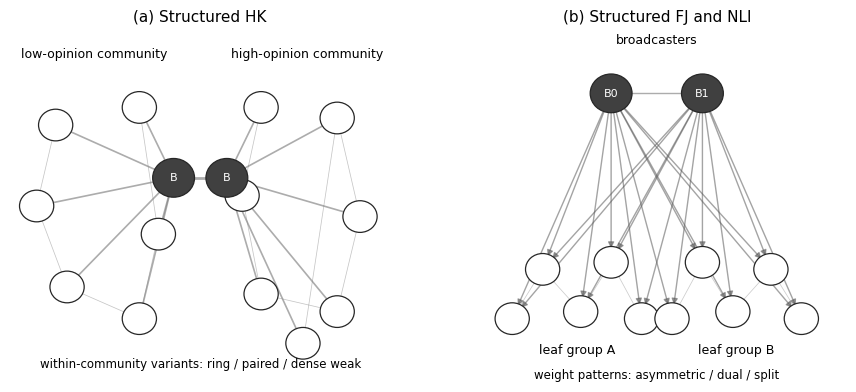

In [20]:

# Compact two-panel schematic for the structured benchmark construction.
# This replaces the old six similar setup plots in the benchmark-description section.
from matplotlib.patches import Circle, FancyArrowPatch


def draw_edge(ax, p1, p2, lw=0.8, alpha=0.65, arrow=False):
    if arrow:
        patch = FancyArrowPatch(
            p1, p2,
            arrowstyle="-|>",
            mutation_scale=9,
            linewidth=lw,
            color="0.35",
            alpha=alpha,
            shrinkA=10,
            shrinkB=10,
        )
        ax.add_patch(patch)
    else:
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color="0.50", linewidth=lw, alpha=alpha, zorder=1)


def draw_node(ax, p, label=None, important=False):
    radius = 0.055 if important else 0.045
    face = "0.25" if important else "white"
    text_color = "white" if important else "0.15"
    circ = Circle(p, radius=radius, facecolor=face, edgecolor="0.15", linewidth=0.9, zorder=3)
    ax.add_patch(circ)
    if label is not None:
        ax.text(p[0], p[1], label, ha="center", va="center", fontsize=8, color=text_color, zorder=4)


fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4), gridspec_kw={"wspace": 0.20})

# (a) HK: two opinion communities linked by bridge nodes.
ax = axes[0]
left_leaf = [(0.12, 0.73), (0.07, 0.50), (0.15, 0.27), (0.34, 0.18), (0.39, 0.42), (0.34, 0.78)]
right_leaf = [(0.66, 0.78), (0.61, 0.53), (0.66, 0.25), (0.86, 0.20), (0.92, 0.47), (0.86, 0.75), (0.77, 0.11)]
bridge_l = (0.43, 0.58)
bridge_r = (0.57, 0.58)

for p in left_leaf:
    draw_edge(ax, bridge_l, p, lw=1.2)
for p in right_leaf:
    draw_edge(ax, bridge_r, p, lw=1.2)
draw_edge(ax, bridge_l, bridge_r, lw=2.0)

# Show only a few weak within-group links to convey that the three families differ there.
for seq in [left_leaf, right_leaf]:
    for p1, p2 in zip(seq[:-1], seq[1:]):
        draw_edge(ax, p1, p2, lw=0.55, alpha=0.45)

for p in left_leaf + right_leaf:
    draw_node(ax, p)
draw_node(ax, bridge_l, "B", important=True)
draw_node(ax, bridge_r, "B", important=True)
ax.text(0.22, 0.92, "low-opinion community", ha="center", fontsize=9)
ax.text(0.78, 0.92, "high-opinion community", ha="center", fontsize=9)
ax.text(0.50, 0.04, "within-community variants: ring / paired / dense weak", ha="center", fontsize=8.5)
ax.set_title("(a) Structured HK")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")

# (b) Broadcast: two influential broadcasters over two leaf groups.
ax = axes[1]
b0, b1 = (0.38, 0.82), (0.62, 0.82)
group_a = [(0.12, 0.18), (0.20, 0.32), (0.30, 0.20), (0.38, 0.34), (0.46, 0.18)]
group_b = [(0.54, 0.18), (0.62, 0.34), (0.70, 0.20), (0.80, 0.32), (0.88, 0.18)]

for p in group_a + group_b:
    draw_edge(ax, b0, p, lw=1.0, alpha=0.55, arrow=True)
    draw_edge(ax, b1, p, lw=1.0, alpha=0.55, arrow=True)
for seq in [group_a, group_b]:
    for p1, p2 in zip(seq[:-1], seq[1:]):
        draw_edge(ax, p1, p2, lw=0.55, alpha=0.4)

draw_edge(ax, b0, b1, lw=1.0, alpha=0.65)
draw_node(ax, b0, "B0", important=True)
draw_node(ax, b1, "B1", important=True)
for p in group_a + group_b:
    draw_node(ax, p)

ax.text(0.29, 0.08, "leaf group A", ha="center", fontsize=9)
ax.text(0.71, 0.08, "leaf group B", ha="center", fontsize=9)
ax.text(0.50, 0.96, "broadcasters", ha="center", fontsize=9)
ax.text(0.50, 0.01, "weight patterns: asymmetric / dual / split", ha="center", fontsize=8.5)
ax.set_title("(b) Structured FJ and NLI")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")

fig.subplots_adjust(top=0.88, bottom=0.08)
save_figure(fig, "fig00_structured_benchmark_schematic_bw")
plt.show()
plt.close(fig)


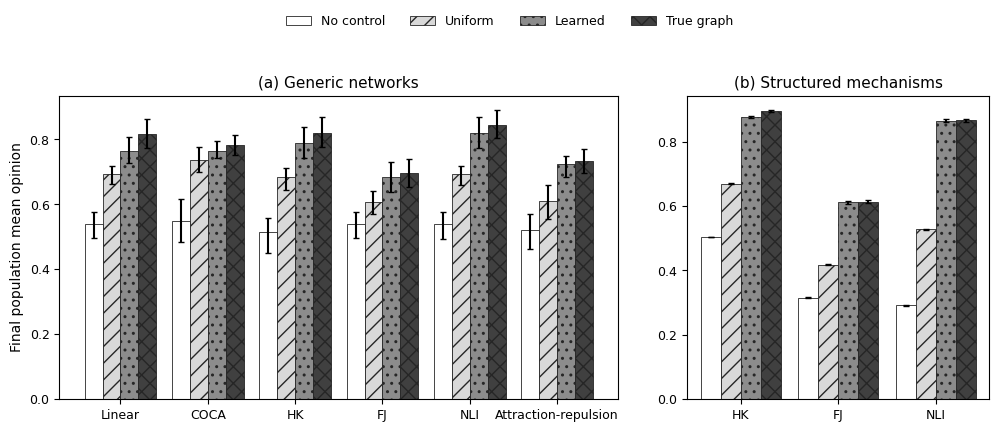

In [21]:

# Figure 1: single-shot control performance.

def grouped_policy_bars(ax, source_df, dynamics_order, title):
    plot_policies = ["No control", "Uniform", "Learned", "True graph"]
    plot_columns = {
        "No control": "no_control",
        "Uniform": "uniform",
        "Learned": "learned",
        "True graph": "true_graph",
    }
    x = np.arange(len(dynamics_order))
    width = 0.82 / len(plot_policies)

    for p_index, label in enumerate(plot_policies):
        col = plot_columns[label]
        means, lows, highs = [], [], []
        for d_index, dynamics in enumerate(dynamics_order):
            g = source_df[source_df["dynamics"] == dynamics]
            mean, low, high = mean_ci_for_group(g, col, seed=20262012 + 100 * p_index + d_index)
            means.append(mean); lows.append(low); highs.append(high)
        means = np.asarray(means, dtype=float)
        lows = np.asarray(lows, dtype=float)
        highs = np.asarray(highs, dtype=float)
        yerr = np.vstack([means - lows, highs - means])
        style = POLICY_STYLE[label]
        offset = (p_index - (len(plot_policies) - 1) / 2) * width
        ax.bar(
            x + offset,
            means,
            width=width,
            yerr=yerr,
            capsize=2,
            color=style["color"],
            edgecolor=style["edgecolor"],
            linewidth=0.6,
            hatch=style["hatch"],
            label=label,
        )
    ax.set_xticks(x)
    ax.set_xticklabels([DYNAMICS_LABELS[d] for d in dynamics_order])
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6), gridspec_kw={"width_ratios": [1.85, 1.0], "wspace": 0.16})
grouped_policy_bars(axes[0], ss_env[ss_env["scenario_class"] == "unstructured_random"], DYNAMICS_ORDER, "(a) Generic networks")
grouped_policy_bars(axes[1], ss_env[ss_env["scenario_class"] == "structured_mechanism"], STRUCTURED_ORDER, "(b) Structured mechanisms")
axes[0].set_ylabel("Final population mean opinion")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.02), frameon=False)
fig.subplots_adjust(top=0.82, bottom=0.16)
save_figure(fig, "fig01_single_shot_control_overview_bw")
plt.show()
plt.close(fig)


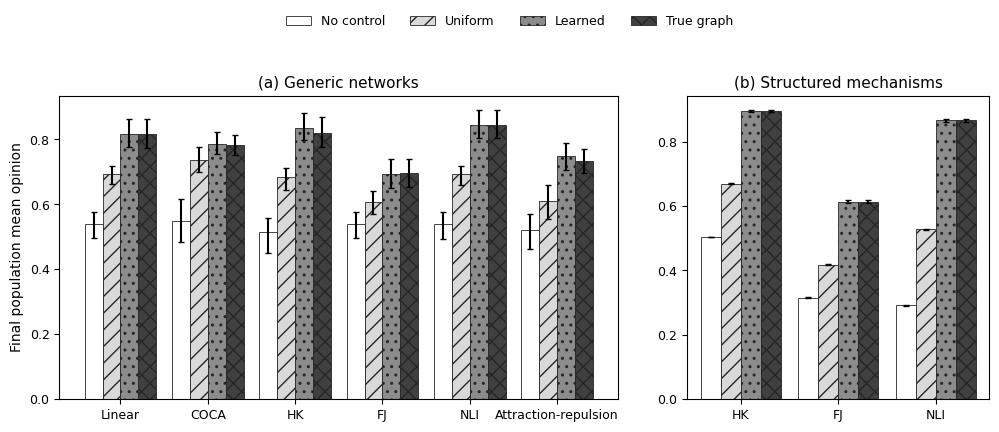

In [22]:

# Figure 2: abundant-data control performance.
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6), gridspec_kw={"width_ratios": [1.85, 1.0], "wspace": 0.16})
grouped_policy_bars(axes[0], ab_env[ab_env["scenario_class"] == "unstructured_random"], DYNAMICS_ORDER, "(a) Generic networks")
grouped_policy_bars(axes[1], ab_env[ab_env["scenario_class"] == "structured_mechanism"], STRUCTURED_ORDER, "(b) Structured mechanisms")
axes[0].set_ylabel("Final population mean opinion")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.02), frameon=False)
fig.subplots_adjust(top=0.82, bottom=0.16)
save_figure(fig, "fig02_abundant_control_overview_bw")
plt.show()
plt.close(fig)


,Regime,dynamics,Uniform_mean,Uniform_ci_low,Uniform_ci_high,Learned_mean,Learned_ci_low,Learned_ci_high,True graph_mean,True graph_ci_low,True graph_ci_high
0,Single-shot,friedkinjohnsen,0.1333,0.1333,0.1333,0.9870,0.9782,0.9957,1.0,1.0,1.0
1,Single-shot,hegselmannkrause,0.1333,0.1333,0.1333,0.8692,0.8600,0.8784,1.0,1.0,1.0
2,Single-shot,nonlinearinfluence,0.1333,0.1333,0.1333,1.0000,1.0000,1.0000,1.0,1.0,1.0
3,Abundant,friedkinjohnsen,0.1333,0.1333,0.1333,1.0000,1.0000,1.0000,1.0,1.0,1.0
4,Abundant,hegselmannkrause,0.1333,0.1333,0.1333,1.0000,1.0000,1.0000,1.0,1.0,1.0
5,Abundant,nonlinearinfluence,0.1333,0.1333,0.1333,1.0000,1.0000,1.0000,1.0,1.0,1.0


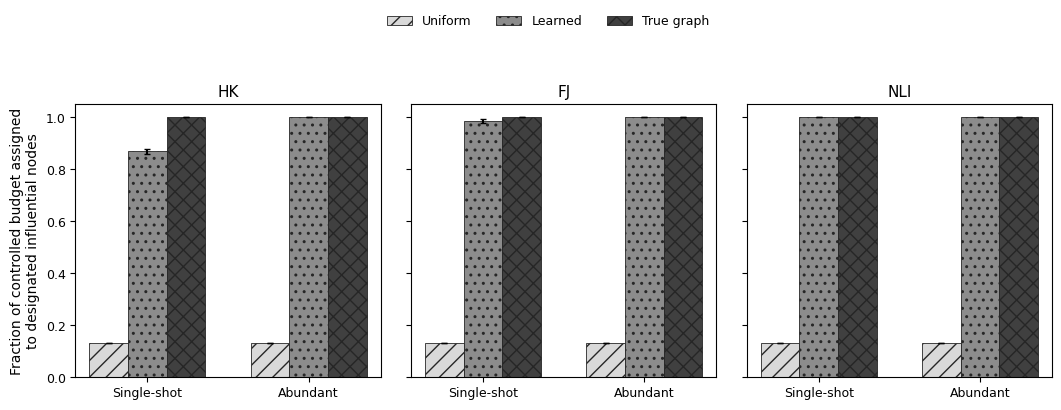

In [23]:

# Figure 3: structured mechanism-targeting.
# This is the compact replacement for the old many-panel structured figure.

def build_targeting_summary(ss_env, ab_env):
    rows = []
    for scenario_class, env_df in [("Single-shot", ss_env), ("Abundant", ab_env)]:
        structured = env_df[env_df["scenario_class"] == "structured_mechanism"].copy()
        for dynamics, g in structured.groupby("dynamics", sort=False):
            row = {
                "Regime": scenario_class,
                "dynamics": dynamics,
            }
            for label, col in [
                ("Uniform", "uniform_hub_budget_fraction"),
                ("Learned", "learned_hub_budget_fraction"),
                ("True graph", "true_graph_hub_budget_fraction"),
            ]:
                if col in g.columns:
                    mean, low, high = mean_ci_for_group(g, col, seed=20263012 + len(rows) * 100 + len(label))
                    row[f"{label}_mean"] = mean
                    row[f"{label}_ci_low"] = low
                    row[f"{label}_ci_high"] = high
            rows.append(row)
    return pd.DataFrame(rows)


targeting_summary = build_targeting_summary(ss_env, ab_env)
targeting_summary.to_csv(TABLE_DIR / "table_structured_targeting_by_dynamics.csv", index=False)
display(targeting_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.4), sharey=True, gridspec_kw={"wspace": 0.10})
for ax, dynamics in zip(axes, STRUCTURED_ORDER):
    sub = targeting_summary[targeting_summary["dynamics"] == dynamics].set_index("Regime")
    x = np.arange(2)
    width = 0.24
    for p_index, label in enumerate(["Uniform", "Learned", "True graph"]):
        means = np.asarray([sub.loc[regime, f"{label}_mean"] for regime in ["Single-shot", "Abundant"]], dtype=float)
        lows = np.asarray([sub.loc[regime, f"{label}_ci_low"] for regime in ["Single-shot", "Abundant"]], dtype=float)
        highs = np.asarray([sub.loc[regime, f"{label}_ci_high"] for regime in ["Single-shot", "Abundant"]], dtype=float)
        yerr = np.vstack([means - lows, highs - means])
        style = POLICY_STYLE[label]
        ax.bar(
            x + (p_index - 1) * width,
            means,
            width=width,
            yerr=yerr,
            capsize=2,
            color=style["color"],
            edgecolor=style["edgecolor"],
            linewidth=0.6,
            hatch=style["hatch"],
            label=label,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(["Single-shot", "Abundant"])
    ax.set_title(DYNAMICS_LABELS[dynamics])
axes[0].set_ylabel("Fraction of controlled budget assigned\nto designated influential nodes")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.03), frameon=False)
fig.subplots_adjust(top=0.80, bottom=0.18)
save_figure(fig, "fig03_structured_targeting_bw")
plt.show()
plt.close(fig)


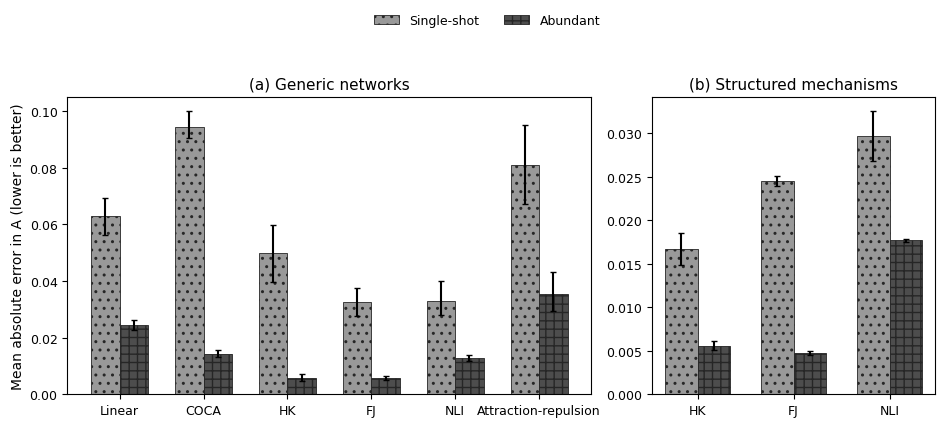

In [24]:

# Figure 4: direct A recovery.
RECOVERY_STYLE = {
    "Single-shot": {"color": "0.60", "hatch": "..", "edgecolor": "0.15"},
    "Abundant": {"color": "0.30", "hatch": "++", "edgecolor": "0.15"},
}

def recovery_panel(ax, scenario_class, dynamics_order, title):
    x = np.arange(len(dynamics_order))
    width = 0.34
    for idx, regime in enumerate(["Single-shot", "Abundant"]):
        sub = recovery[(recovery["scenario_class"] == scenario_class) & (recovery["regime"] == regime)]
        means, lows, highs = [], [], []
        for d_index, dynamics in enumerate(dynamics_order):
            g = sub[sub["dynamics"] == dynamics]
            mean, low, high = mean_ci_for_group(g, "A_MAE", seed=20264012 + 100 * idx + d_index)
            means.append(mean); lows.append(low); highs.append(high)
        means = np.asarray(means, dtype=float)
        lows = np.asarray(lows, dtype=float)
        highs = np.asarray(highs, dtype=float)
        yerr = np.vstack([means - lows, highs - means])
        style = RECOVERY_STYLE[regime]
        offset = (-0.5 if regime == "Single-shot" else 0.5) * width
        ax.bar(
            x + offset,
            means,
            width=width,
            yerr=yerr,
            capsize=2,
            color=style["color"],
            edgecolor=style["edgecolor"],
            linewidth=0.6,
            hatch=style["hatch"],
            label=regime,
        )
    ax.set_xticks(x)
    ax.set_xticklabels([DYNAMICS_LABELS[d] for d in dynamics_order])
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.5), gridspec_kw={"width_ratios": [1.85, 1.0], "wspace": 0.15})
recovery_panel(axes[0], "unstructured_random", DYNAMICS_ORDER, "(a) Generic networks")
recovery_panel(axes[1], "structured_mechanism", STRUCTURED_ORDER, "(b) Structured mechanisms")
axes[0].set_ylabel("Mean absolute error in A (lower is better)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.03), frameon=False)
fig.subplots_adjust(top=0.82, bottom=0.16)
save_figure(fig, "fig04_A_recovery_bw")
plt.show()
plt.close(fig)


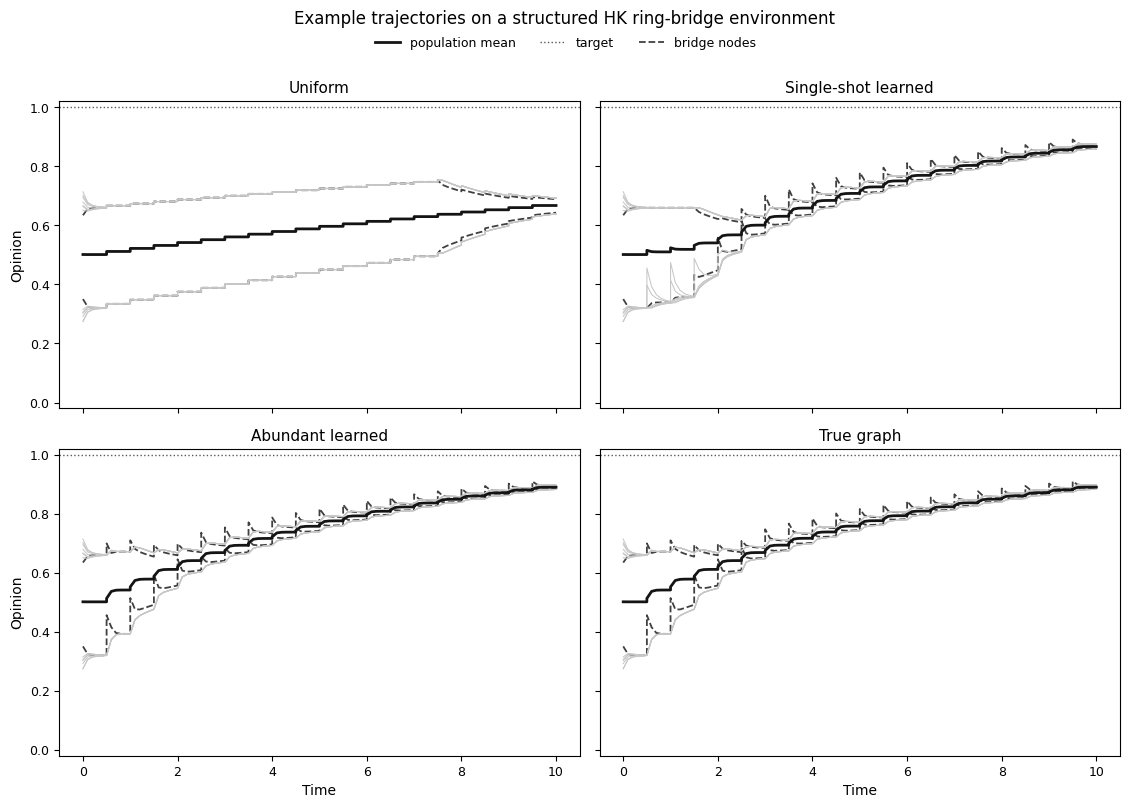

In [25]:

# Figure 5: example node trajectories.
# Structured HK is used because the two opinion communities and bridge-node effect are visually interpretable.
T_CAMPAIGN = float(ss_manifest["scientific_config"]["t_campaign"])
T_S = float(ss_manifest["scientific_config"]["t_s"])
TARGET = float(ss_manifest["scientific_config"]["target"])


def _load_policy_from_npz(arrays, policy):
    inter_keys = sorted(key for key in arrays.files if key.startswith(f"{policy}__intermediate__"))
    return {
        "policy": policy,
        "states": np.asarray(arrays[f"{policy}__states"], dtype=float),
        "actions": np.asarray(arrays[f"{policy}__actions"], dtype=float),
        "intermediate_states_list": [np.asarray(arrays[key], dtype=float) for key in inter_keys],
    }


def load_ss_baseline_rollout(environment_id, policy):
    cache_dir = Path(SS_CACHE_INDEX[environment_id]["cache_dir"])
    arrays = np.load(cache_dir / "baselines.npz", allow_pickle=False)
    return _load_policy_from_npz(arrays, policy)


def load_ss_learned_rollout(environment_id, learning_seed):
    cache_dir = Path(SS_CACHE_INDEX[environment_id]["cache_dir"])
    matches = list((cache_dir / "learned").glob(f"seed_{int(learning_seed):02d}_*/rollout.npz"))
    if len(matches) != 1:
        raise RuntimeError(
            f"Expected exactly one single-shot rollout for {environment_id}, seed {learning_seed}; found {len(matches)}"
        )
    arrays = np.load(matches[0], allow_pickle=False)
    return _load_policy_from_npz(arrays, "learned_nonlinear")


def load_ab_learned_rollout(environment_id, learning_seed):
    env_dir = AB_CACHE_ROOT / environment_id
    path = env_dir / f"learned_seed_{int(learning_seed):02d}_rollout.npz"
    if not path.exists():
        raise FileNotFoundError(path)
    arrays = np.load(path, allow_pickle=False)
    inter_keys = sorted(key for key in arrays.files if key.startswith("intermediate__"))
    return {
        "policy": "learned_abundant_nonlinear",
        "states": np.asarray(arrays["states"], dtype=float),
        "actions": np.asarray(arrays["actions"], dtype=float),
        "intermediate_states_list": [np.asarray(arrays[key], dtype=float) for key in inter_keys],
    }


def fine_trajectory(rollout):
    times = [0.0]
    states = [np.asarray(rollout["states"][0], dtype=float)]
    for campaign, inter in enumerate(rollout["intermediate_states_list"]):
        inter = np.asarray(inter, dtype=float)
        t0 = campaign * T_CAMPAIGN
        times.append(t0)
        states.append(inter[0])
        for step in range(1, len(inter)):
            times.append(t0 + step * T_S)
            states.append(inter[step])
    return np.asarray(times, dtype=float), np.asarray(states, dtype=float)


def representative_seed(df, environment_id, policy, score_col):
    rows = df[(df["policy"] == policy) & (df["environment_id"] == environment_id)].copy()
    if rows.empty:
        raise RuntimeError(f"No rows found for {environment_id}, policy={policy}")
    median_value = float(rows[score_col].median())
    idx = (rows[score_col] - median_value).abs().idxmin()
    return int(rows.loc[idx, "learning_seed"])


example_env = "structured__hegselmannkrause__ring_bridge__env00"
ss_seed = representative_seed(ss_raw, example_env, SS_LEARNED, "final_mean")
ab_seed = representative_seed(ab_raw, example_env, AB_LEARNED, "mean_end")

rollouts = [
    ("Uniform", load_ss_baseline_rollout(example_env, "uniform")),
    ("Single-shot learned", load_ss_learned_rollout(example_env, ss_seed)),
    ("Abundant learned", load_ab_learned_rollout(example_env, ab_seed)),
    ("True graph", load_ss_baseline_rollout(example_env, "true_graph")),
]

bridge_nodes = {0, 7}
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (title, rollout) in zip(axes, rollouts):
    times, states = fine_trajectory(rollout)
    for node in range(states.shape[1]):
        if node in bridge_nodes:
            ax.plot(times, states[:, node], color="0.25", linewidth=1.3, linestyle="--")
        else:
            ax.plot(times, states[:, node], color="0.78", linewidth=0.75)
    ax.plot(times, states.mean(axis=1), color="0.08", linewidth=2.0, label="population mean")
    ax.axhline(TARGET, color="0.35", linestyle=":", linewidth=1.0, label="target")
    ax.set_title(title)
    ax.set_ylim(-0.02, 1.02)
    ax.grid(False)

# Add one bridge-node legend proxy only once.
axes[0].plot([], [], color="0.25", linewidth=1.3, linestyle="--", label="bridge nodes")
axes[0].set_ylabel("Opinion")
axes[2].set_ylabel("Opinion")
axes[2].set_xlabel("Time")
axes[3].set_xlabel("Time")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.01), frameon=False)
fig.suptitle("Example trajectories on a structured HK ring-bridge environment", y=1.03)
fig.tight_layout()
save_figure(fig, "fig05_example_HK_node_trajectories_bw")
plt.show()
plt.close(fig)


In [26]:

# Compact paper-facing exports.

def display_table_for_paper(df, regime_name):
    show = df[[
        "Benchmark", "Dynamics",
        "No control_mean", "Uniform_mean", "Learned_mean", "True graph_mean",
        "Learned_minus_uniform_mean", "Learned_minus_uniform_ci_low", "Learned_minus_uniform_ci_high",
        "Win_rate_vs_uniform",
    ]].copy()
    display(show.round(4))
    show.to_latex(
        TABLE_DIR / f"paper_{regime_name}_main_table.tex",
        index=False,
        float_format="%.4f",
        escape=False,
    )
    return show


single_shot_display = display_table_for_paper(single_shot_table, "single_shot")
abundant_display = display_table_for_paper(abundant_table, "abundant")

true_model_display = true_model_oracle[[
    "Benchmark", "Dynamics",
    "Uniform_mean", "Single-shot_mean", "Abundant_mean", "True graph_mean", "True model_mean",
]].copy()
true_model_display.to_latex(
    TABLE_DIR / "paper_true_model_oracle_table.tex",
    index=False,
    float_format="%.4f",
    escape=False,
)

A_recovery_display = A_recovery_table[[
    "Benchmark", "Dynamics", "Regime", "A_MAE_mean", "A_MAE_ci_low", "A_MAE_ci_high"
]].copy()
A_recovery_display.to_latex(
    TABLE_DIR / "paper_A_recovery_table.tex",
    index=False,
    float_format="%.4f",
    escape=False,
)

summary_manifest = pd.DataFrame([
    {"type": "figure", "file": "fig00_structured_benchmark_schematic_bw.pdf", "purpose": "Compact replacement for the old six-panel structured setup figure"},
    {"type": "figure", "file": "fig01_single_shot_control_overview_bw.pdf", "purpose": "Single-shot performance overview"},
    {"type": "figure", "file": "fig02_abundant_control_overview_bw.pdf", "purpose": "Abundant-data performance overview"},
    {"type": "figure", "file": "fig03_structured_targeting_bw.pdf", "purpose": "Mechanism-targeted intervention on structured cases"},
    {"type": "figure", "file": "fig04_A_recovery_bw.pdf", "purpose": "Direct A-recovery comparison"},
    {"type": "figure", "file": "fig05_example_HK_node_trajectories_bw.pdf", "purpose": "Representative structured-HK node trajectories"},
    {"type": "table", "file": "paper_single_shot_main_table.tex", "purpose": "Single-shot main table"},
    {"type": "table", "file": "paper_abundant_main_table.tex", "purpose": "Abundant-data main table"},
    {"type": "table", "file": "paper_true_model_oracle_table.tex", "purpose": "Linear/NLI true-model oracle comparison"},
    {"type": "table", "file": "paper_A_recovery_table.tex", "purpose": "A-recovery table"},
    {"type": "table", "file": "table_prediction_quality_supporting.csv", "purpose": "Supporting one-step prediction MAE ratio, if present in final summaries"},
])
summary_manifest.to_csv(TABLE_DIR / "manifest_results_storyline.csv", index=False)
display(summary_manifest)

print("Figures written to:", FIG_DIR)
print("Tables written to:", TABLE_DIR)
print("FINAL RESULTS-STORYLINE ANALYSIS COMPLETE")


,Benchmark,Dynamics,No control_mean,Uniform_mean,Learned_mean,True graph_mean,Learned_minus_uniform_mean,Learned_minus_uniform_ci_low,Learned_minus_uniform_ci_high,Win_rate_vs_uniform
0,Generic,Linear,0.5410,0.6937,0.7636,0.8164,0.0700,0.0434,0.1007,1.00
1,Generic,COCA,0.5486,0.7365,0.7640,0.7819,0.0274,0.0108,0.0479,0.92
2,Generic,HK,0.5154,0.6856,0.7902,0.8211,0.1047,0.0722,0.1417,1.00
3,Generic,FJ,0.5404,0.6088,0.6844,0.6956,0.0756,0.0513,0.0995,1.00
4,Generic,NLI,0.5402,0.6931,0.8201,0.8447,0.1270,0.0970,0.1598,1.00
5,Generic,Attraction-repulsion,0.5209,0.6109,0.7231,0.7348,0.1122,0.0644,0.1615,0.96
6,Structured,HK,0.5028,0.6698,0.8764,0.8954,0.2066,0.2041,0.2091,1.00
7,Structured,FJ,0.3148,0.4172,0.6113,0.6138,0.1941,0.1893,0.1989,1.00
8,Structured,NLI,0.2923,0.5276,0.8650,0.8656,0.3374,0.3317,0.3431,1.00


,Benchmark,Dynamics,No control_mean,Uniform_mean,Learned_mean,True graph_mean,Learned_minus_uniform_mean,Learned_minus_uniform_ci_low,Learned_minus_uniform_ci_high,Win_rate_vs_uniform
0,Generic,Linear,0.5410,0.6937,0.8184,0.8164,0.1248,0.0976,0.1536,1.0
1,Generic,COCA,0.5486,0.7365,0.7875,0.7819,0.0509,0.0376,0.0657,1.0
2,Generic,HK,0.5154,0.6856,0.8364,0.8211,0.1508,0.1194,0.1847,1.0
3,Generic,FJ,0.5404,0.6088,0.6946,0.6956,0.0858,0.0663,0.1062,1.0
4,Generic,NLI,0.5402,0.6931,0.8450,0.8447,0.1519,0.1244,0.1800,1.0
5,Generic,Attraction-repulsion,0.5209,0.6109,0.7491,0.7348,0.1382,0.0981,0.1865,1.0
6,Structured,HK,0.5028,0.6698,0.8951,0.8954,0.2254,0.2234,0.2273,1.0
7,Structured,FJ,0.3148,0.4172,0.6138,0.6138,0.1966,0.1919,0.2013,1.0
8,Structured,NLI,0.2923,0.5276,0.8655,0.8656,0.3379,0.3319,0.3438,1.0


,type,file,purpose
0,figure,fig00_structured_benchmark_schematic_bw.pdf,Compact replacement for the old six-panel stru...
1,figure,fig01_single_shot_control_overview_bw.pdf,Single-shot performance overview
2,figure,fig02_abundant_control_overview_bw.pdf,Abundant-data performance overview
3,figure,fig03_structured_targeting_bw.pdf,Mechanism-targeted intervention on structured ...
4,figure,fig04_A_recovery_bw.pdf,Direct A-recovery comparison
5,figure,fig05_example_HK_node_trajectories_bw.pdf,Representative structured-HK node trajectories
6,table,paper_single_shot_main_table.tex,Single-shot main table
7,table,paper_abundant_main_table.tex,Abundant-data main table
8,table,paper_true_model_oracle_table.tex,Linear/NLI true-model oracle comparison
9,table,paper_A_recovery_table.tex,A-recovery table


Figures written to: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_12_results_storyline_fixed\figures
Tables written to: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_12_results_storyline_fixed\tables
FINAL RESULTS-STORYLINE ANALYSIS COMPLETE
